In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder
import os

In [4]:
 sales = pd.read_parquet('/content/done_sales.parquet')
 prices = pd.read_parquet('/content/done_prices.parquet')
 calendar = pd.read_parquet('/content/done_cal.parquet')

## 🔍 Tạo đặc trưng thời gian từ dữ liệu demand

Để mô hình dự đoán chính xác hơn, ta tạo ra các đặc trưng từ dữ liệu quá khứ, đồng thời mong muốn học được món hàng đang được dự đoán có đang nằm gần hoặc trong xu hướng hay không:

- **Lag features**: Doanh thu tại các mốc thời gian lùi lại, ví dụ 7 hoặc 28 ngày trước. Điều này giúp mô hình nhận biết chu kỳ tuần / tháng.
- **Rolling mean features**: Trung bình động trong 7 hoặc 28 ngày gần mốc lag, giúp mô hình hiểu xu hướng tăng giảm của nhu cầu.
- Tất cả đặc trưng đều được tính theo từng `id` (mỗi sản phẩm tại từng cửa hàng cụ thể).

Hàm `demand_features(df)` sẽ tự động tạo ra các cột này để sử dụng trong huấn luyện mô hình.

Để hiểu rõ hơn ví dụ nếu như là lag_t7 cho ngày thứ 100 của món hàng A sẽ là doanh thu của ngày thứ 93. còn, rolling_mean_lag7_w28 của ngày thứ 100 của món hàng A sẽ là doanh thu trung bình từ ngày 72 (=100 - 28) tới ngày 78 (7 ngày).


In [8]:
from sklearn.model_selection import train_test_split
import lightgbm as lgb
LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """

    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")

    return df

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")

    return out.reset_index()

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """

    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))

    # Add demand features
    df = demand_features(df)

    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]

    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)

    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1

    # Determine list of covariables
    x = list(set(df.columns) - {'id', 'd', 'demand'})

    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    return df, test, x

In [9]:
df, test, x = prep_data(sales, 1000 - 28)

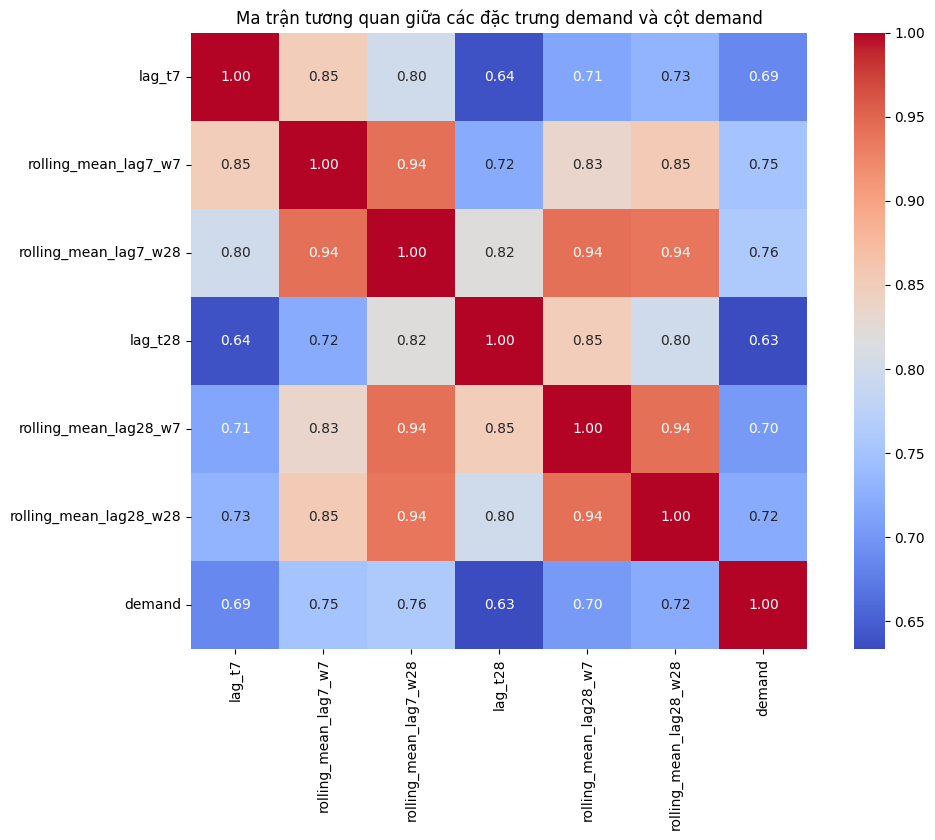

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_demand_feature_correlation(df):
    # Lấy danh sách các cột được tạo bởi demand_features
    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]

    # Thêm cột demand để so sánh tương quan
    corr_cols = demand_cols + ["demand"]

    # Loại bỏ hàng có NaN (do shift và rolling tạo ra)
    df_corr = df[corr_cols].dropna()

    # Tính ma trận tương quan
    corr = df_corr.corr()

    # Vẽ heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
    plt.title("Ma trận tương quan giữa các đặc trưng demand và cột demand")
    plt.show()
plot_demand_feature_correlation(df)


## Nhận xét ma trận tương quan
Thông qua, ma trận dễ dàng thấy demand ảnh hưởng khá nhiều bởi các feature đã được tạo ra. Tuy nhiên, cũng có thể thấy các cột rolling_mean có độ tương quan cao khi bắt cặp với nhau.

Dựa trên, độ tương quan giữa demand và các cột rolling_mean, nhóm quyết định giữ lại rolling_mean_lag7_w7 và rolling_mean_lag7_w28 và xóa đi 2 rolling_mean còn lại vì có độ tương quan cao với 2 rolling_mean_lag7_w7 còn lại

In [ ]:
df.drop(['rolling_mean_lag7_w7', 'rolling_mean_lag7_w28'], axis=1, inplace=True)

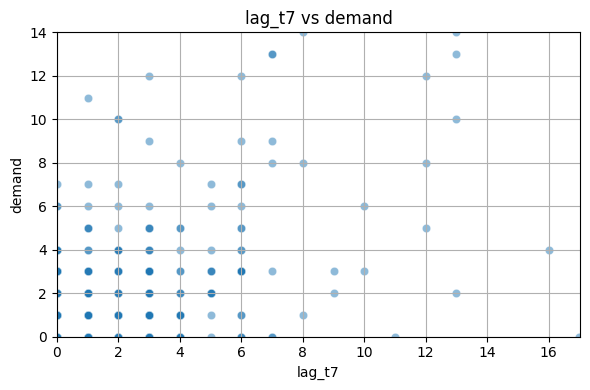

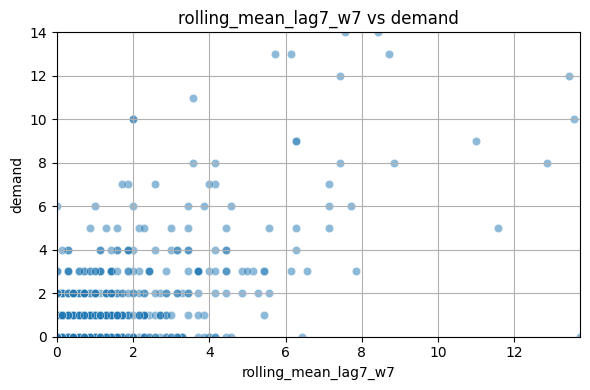

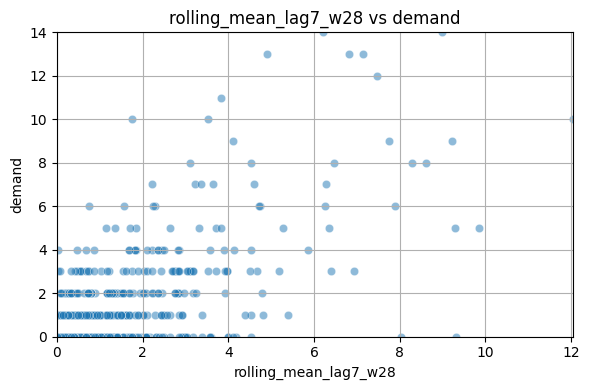

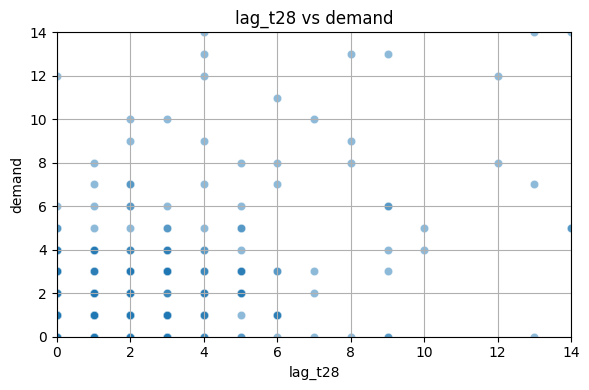

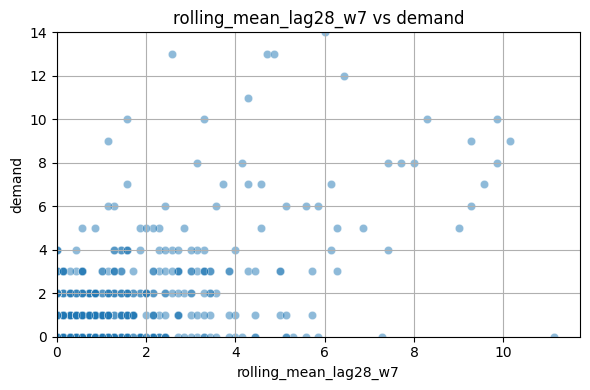

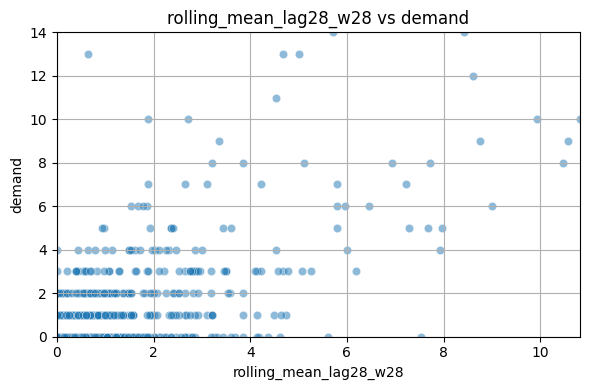

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_demand_feature_scatter(df, sample_size=1000, use_log=False, clip_outliers=True):
    import seaborn as sns
    import matplotlib.pyplot as plt

    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]
    df_sample = df[demand_cols + ["demand"]].dropna().sample(n=sample_size, random_state=42)

    for col in demand_cols:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=df_sample, x=col, y="demand", alpha=0.5)

        if clip_outliers:
            plt.xlim(df_sample[col].quantile(0.01), df_sample[col].quantile(0.99))
            plt.ylim(df_sample["demand"].quantile(0.01), df_sample["demand"].quantile(0.99))

        if use_log:
            plt.xscale("log")
            plt.yscale("log")

        plt.title(f"{col} vs demand")
        plt.xlabel(col)
        plt.ylabel("demand")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

plot_demand_feature_scatter(df)
